# Text-Based Personality Generation using an MLP

**Dataset:** Big Five Personality Test / IPIP-FFM from Kaggle  
**Main model:** Multi-Layer Perceptron (MLP) for multi-output regression  
**Output:** Five trait scores (1–5) and a short text profile

## Project objective

Use the 50 questionnaire responses as input, predict five Big Five trait scores with a small neural network, and turn the scores into a readable personality summary.

### What this notebook does

1. Loads the downloaded dataset with `pandas.read_csv()` and automatically detects comma-separated or tab-separated files.
2. Cleans invalid/missing responses and calculates the five trait scores using reverse scoring.
3. Explores the data with several useful visualizations.
4. Splits the data into training and test sets and scales inputs without fitting the scaler on the test set.
5. Trains an MLP and compares it with a simple Linear Regression baseline.
6. Evaluates the models with MAE, RMSE, and R², then plots prediction errors.
7. Generates a short text profile for a sample person and includes an optional 50-question interactive test.
8. Saves the trained model and supporting files in an `output` folder.


## 1. Setup

Install any missing libraries in your notebook environment. Run this only if the imports below fail:

```python
%pip install pandas numpy matplotlib seaborn scikit-learn tensorflow joblib
```

The model uses a small, two-hidden-layer MLP. To keep training manageable on a typical laptop, the default configuration uses up to 150,000 valid responses. Change `MAX_ROWS_FOR_MODEL` to `None` if you specifically want to train on every valid row and have enough memory/time.

In [1]:
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

os.makedirs("output", exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Output folder: output/")

TensorFlow version: 2.21.0
Output folder: output/


## 2. Load the downloaded dataset

Set `DATA_PATH` to the exact filename or path where you saved the Kaggle file. The starting notebook used `five_big_personality_dataset.csv`. If your Kaggle download is still named `data-final.csv`, change the line below to that filename.

The original file can be tab-separated even when it ends in `.csv`. The code checks the first few thousand characters and selects the delimiter, then loads only the 50 questionnaire columns to reduce memory use.

In [2]:
# EDIT THIS if your downloaded dataset has a different name or folder location.
DATA_PATH = "data-final.csv"  # Or "data-final.csv" if that is your downloaded filename

if not os.path.exists(DATA_PATH):
    nearby_files = [name for name in os.listdir(".") if name.lower().endswith((".csv", ".txt", ".data"))]
    raise FileNotFoundError(
        f"Cannot find '{DATA_PATH}'. Set DATA_PATH to your dataset path. "
        f"CSV/TXT files in the current folder: {nearby_files[:20]}"
    )

# Detect whether the file uses tabs or commas.
with open(DATA_PATH, "r", encoding="utf-8-sig", errors="replace") as file:
    sample_text = file.read(8192)
separator = "\t" if sample_text.count("\t") > sample_text.count(",") else ","
print("Detected separator:", "TAB" if separator == "\t" else "COMMA")

# Read only the header first so that we can select the 50 questionnaire columns.
header = pd.read_csv(DATA_PATH, sep=separator, nrows=0, encoding="utf-8-sig")
original_to_clean = {str(col).strip().replace("\ufeff", ""): col for col in header.columns}

prefixes = ["EXT", "EST", "AGR", "CSN", "OPN"]
question_columns = [f"{prefix}{number}" for prefix in prefixes for number in range(1, 11)]
missing_columns = [col for col in question_columns if col not in original_to_clean]

if missing_columns:
    raise ValueError(
        "Some expected questionnaire columns were not found. "
        f"Missing columns: {missing_columns}. Check that this is the 50-item Big Five dataset."
    )

columns_to_read = [original_to_clean[col] for col in question_columns]
df = pd.read_csv(
    DATA_PATH,
    sep=separator,
    usecols=columns_to_read,
    low_memory=False,
    encoding="utf-8-sig"
)
df.columns = [str(col).strip().replace("\ufeff", "") for col in df.columns]
df = df[question_columns]

print(f"Rows loaded: {len(df):,}")
print(f"Questionnaire columns loaded: {len(question_columns)}")
display(df.head())

Detected separator: TAB
Rows loaded: 1,015,341
Questionnaire columns loaded: 50


,EXT1,EXT2,EXT3,EXT4,EXT5,EXT6,EXT7,EXT8,EXT9,EXT10,...,OPN1,OPN2,OPN3,OPN4,OPN5,OPN6,OPN7,OPN8,OPN9,OPN10
0,4.0,1.0,5.0,2.0,5.0,1.0,5.0,2.0,4.0,1.0,...,5.0,1.0,4.0,1.0,4.0,1.0,5.0,3.0,4.0,5.0
1,3.0,5.0,3.0,4.0,3.0,3.0,2.0,5.0,1.0,5.0,...,1.0,2.0,4.0,2.0,3.0,1.0,4.0,2.0,5.0,3.0
2,2.0,3.0,4.0,4.0,3.0,2.0,1.0,3.0,2.0,5.0,...,5.0,1.0,2.0,1.0,4.0,2.0,5.0,3.0,4.0,4.0
3,2.0,2.0,2.0,3.0,4.0,2.0,2.0,4.0,1.0,4.0,...,4.0,2.0,5.0,2.0,3.0,1.0,4.0,4.0,3.0,3.0
4,3.0,3.0,3.0,3.0,5.0,3.0,3.0,5.0,3.0,4.0,...,5.0,1.0,5.0,1.0,5.0,1.0,5.0,3.0,5.0,5.0


## 3. Inspect and clean the responses

Each questionnaire response should be a number from **1 to 5**. Values outside that range, blank cells, and non-numeric responses are marked missing. To calculate a fair score, this notebook keeps rows with all 50 valid answers. It does not remove repeated answer patterns because different people can legitimately give the same responses.

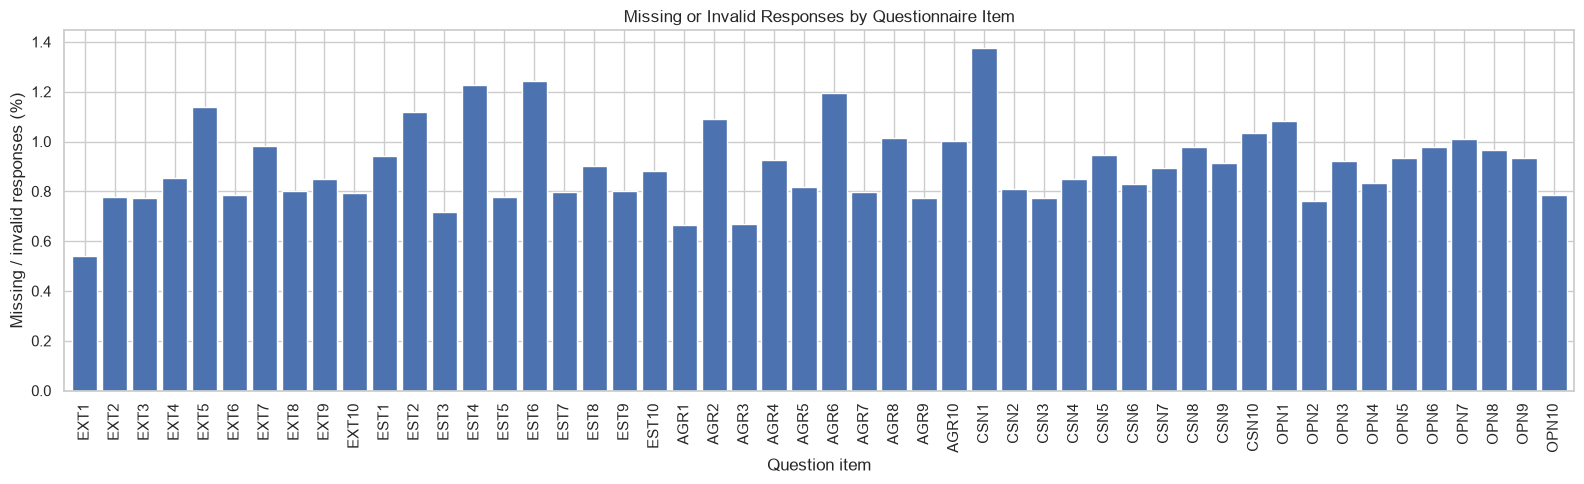

Rows before cleaning: 1,015,341
Rows retained:        874,434
Rows removed:         140,907
Clean input shape: (874434, 50)


In [3]:
rows_before_cleaning = len(df)

# Convert responses to numbers and mark values outside the 1–5 range as missing.
for column in question_columns:
    values = pd.to_numeric(df[column], errors="coerce")
    df[column] = values.where(values.isin([1, 2, 3, 4, 5])).astype("float32")

# Visualize the percentage of missing/invalid answers for each question.
invalid_percent = (df.isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(16, 5))
invalid_percent.reindex(question_columns).plot(kind="bar", width=0.85)
plt.title("Missing or Invalid Responses by Questionnaire Item")
plt.xlabel("Question item")
plt.ylabel("Missing / invalid responses (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

valid_rows = df[question_columns].notna().all(axis=1)
X_all = df.loc[valid_rows, question_columns].reset_index(drop=True).astype("float32")
rows_after_cleaning = len(X_all)
del df

print(f"Rows before cleaning: {rows_before_cleaning:,}")
print(f"Rows retained:        {rows_after_cleaning:,}")
print(f"Rows removed:         {rows_before_cleaning - rows_after_cleaning:,}")
print("Clean input shape:", X_all.shape)

if rows_after_cleaning < 100:
    raise ValueError("Fewer than 100 complete response rows remain. Check the file format and response values.")

## 4. Calculate the Big Five target scores

The five groups of questionnaire items are:

- `EXT`: Extraversion
- `EST`: Emotional Stability items; this project reverses the scale to report **Neuroticism** instead
- `AGR`: Agreeableness
- `CSN`: Conscientiousness
- `OPN`: Openness

Negatively worded items are reverse-scored with `6 - response`. The input `X_all` stays in its original 1–5 response form, while target scores use corrected item directions. This keeps the prediction function consistent with the answers a person would enter.

In [4]:
# Items that must be reverse-scored so a higher score means more of the named trait.
REVERSE_ITEMS = [
    "EXT2", "EXT4", "EXT6", "EXT8", "EXT10",
    "AGR1", "AGR3", "AGR5", "AGR7",
    "CSN2", "CSN4", "CSN6", "CSN8",
    "EST2", "EST4",  # Reverse emotional-stability items to produce Neuroticism
    "OPN2", "OPN4", "OPN6"
]

TRAITS = ["Openness", "Conscientiousness", "Extraversion", "Agreeableness", "Neuroticism"]
TRAIT_PREFIX = {
    "Openness": "OPN",
    "Conscientiousness": "CSN",
    "Extraversion": "EXT",
    "Agreeableness": "AGR",
    "Neuroticism": "EST"
}

def calculate_trait_score(responses, prefix):
    """Calculate one mean trait score from the ten related questionnaire items."""
    item_columns = [f"{prefix}{number}" for number in range(1, 11)]
    scored_items = responses[item_columns].copy()
    for item in item_columns:
        if item in REVERSE_ITEMS:
            scored_items[item] = 6 - scored_items[item]
    return scored_items.mean(axis=1)

y_all = pd.DataFrame({
    trait: calculate_trait_score(X_all, prefix)
    for trait, prefix in TRAIT_PREFIX.items()
})[TRAITS]

print("Input features (X):", X_all.shape)
print("Target scores (y):", y_all.shape)
print("Target score range:")
display(y_all.describe().round(3))
display(y_all.head())

Input features (X): (874434, 50)
Target scores (y): (874434, 5)
Target score range:


,Openness,Conscientiousness,Extraversion,Agreeableness,Neuroticism
count,874434.000,874434.000,874434.00,874434.000,874434.000
mean,3.899,3.366,2.96,3.774,3.067
std,0.630,0.737,0.91,0.729,0.859
min,1.000,1.000,1.00,1.000,1.000
25%,3.500,2.900,2.30,3.300,2.400
50%,3.900,3.400,3.00,3.900,3.100
75%,4.400,3.900,3.60,4.300,3.700
max,5.000,5.000,5.00,5.000,5.000


,Openness,Conscientiousness,Extraversion,Agreeableness,Neuroticism
0,4.5,3.2,4.6,3.9,2.4
1,3.5,3.7,2.0,4.4,2.5
2,4.1,3.4,2.5,4.2,2.6
3,3.9,2.5,2.6,3.8,2.9
4,4.8,4.8,2.9,4.6,1.9


## 5. Exploratory Data Analysis (EDA)

These charts help inspect the score distributions and relationships before training. The analysis uses all valid rows where practical, and a small random sample for charts that would otherwise be slow.

### 5.1 Trait score distributions

The five histograms show how each calculated trait score is distributed in the dataset.

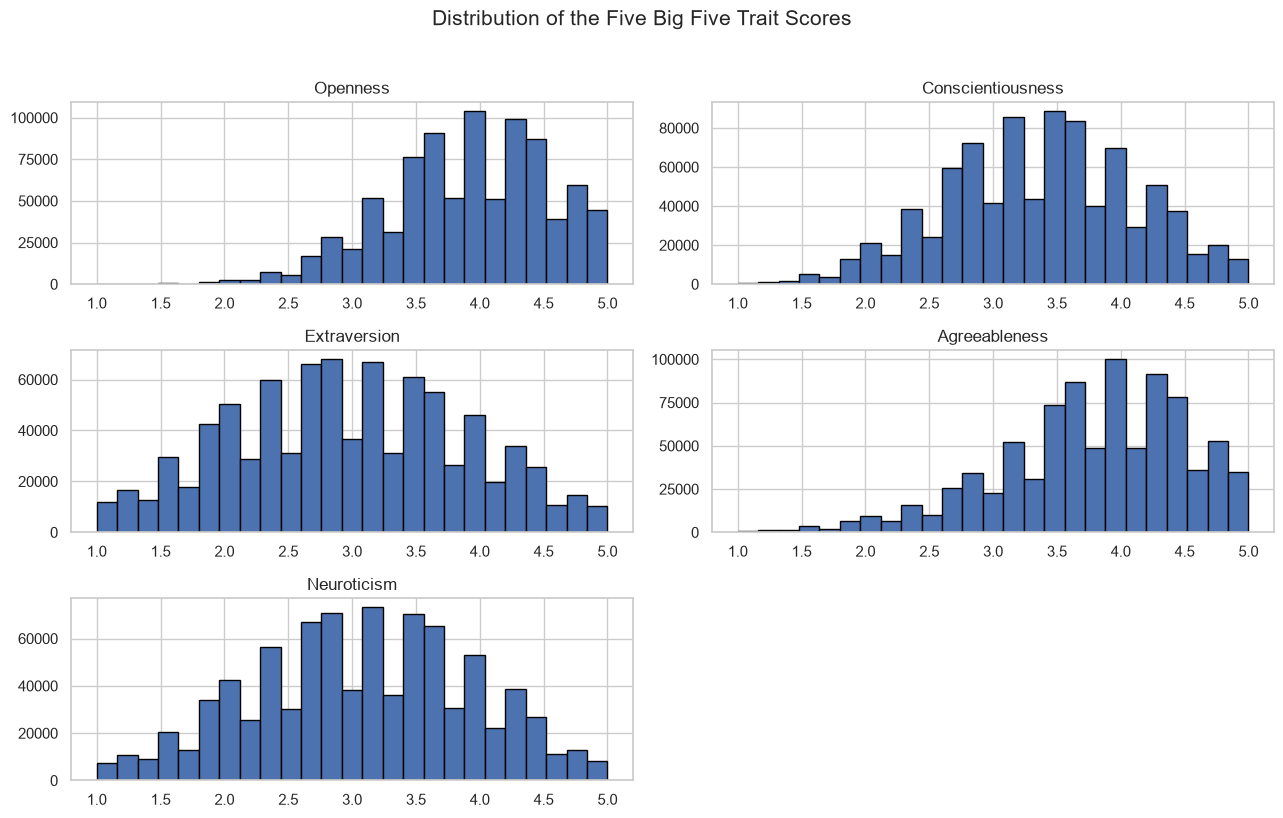

In [5]:
axes = y_all.hist(figsize=(13, 8), bins=25, edgecolor="black")
plt.suptitle("Distribution of the Five Big Five Trait Scores", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

### 5.2 Compare trait score spread

The boxplot compares the median, spread, and potential outliers for all five scores.

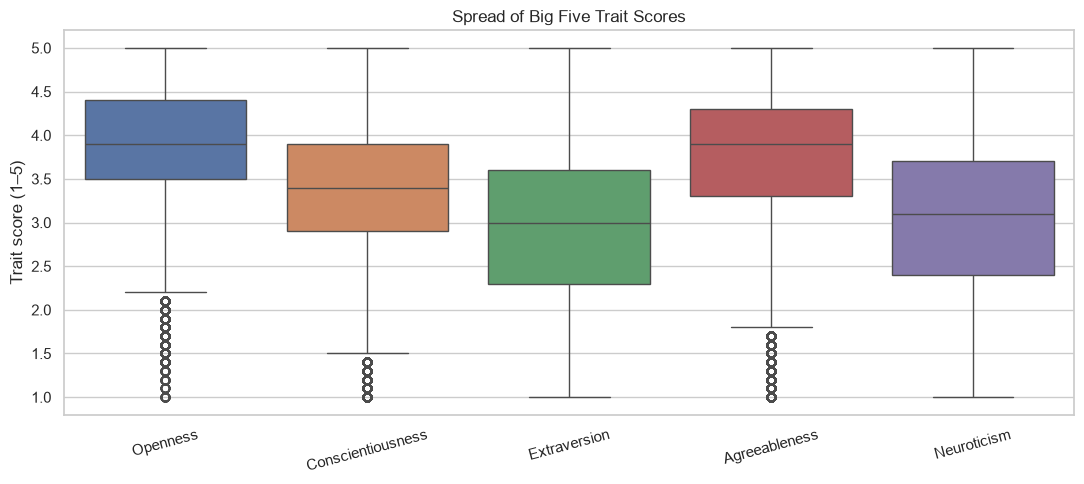

In [6]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=y_all, orient="v")
plt.title("Spread of Big Five Trait Scores")
plt.ylabel("Trait score (1–5)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 5.3 Correlation heatmap

This plot shows correlations between the derived trait scores. Correlation does not mean that one trait causes another.

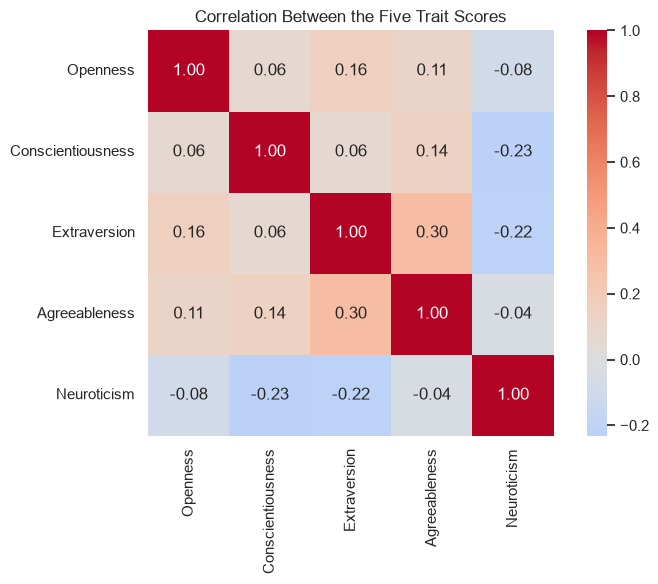

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(y_all.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Between the Five Trait Scores")
plt.tight_layout()
plt.show()

### 5.4 Average response for each questionnaire item

This plot shows raw average responses by item. These are the original answers, before reverse scoring.

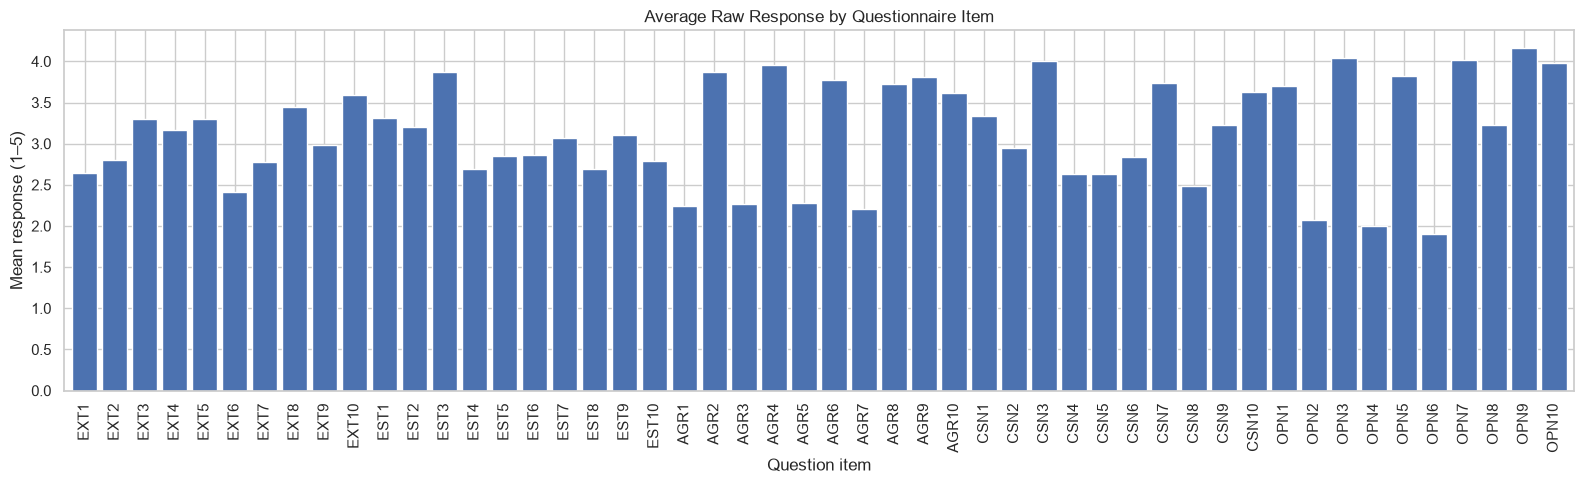

In [8]:
item_means = X_all[question_columns].mean().reindex(question_columns)
plt.figure(figsize=(16, 5))
item_means.plot(kind="bar", width=0.85)
plt.title("Average Raw Response by Questionnaire Item")
plt.xlabel("Question item")
plt.ylabel("Mean response (1–5)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 5.5 Low, Medium, and High score groups

For the text generator, scores below 2.5 are labelled **Low**, scores from 2.5 to below 3.5 are **Medium**, and scores of 3.5 or more are **High**. These cutoffs are simple project rules, not clinical thresholds.

,Low,Medium,High
Openness,15349,192079,667006
Conscientiousness,99258,373134,402042
Extraversion,270724,331674,272036
Agreeableness,47423,210537,616474
Neuroticism,219673,351838,302923


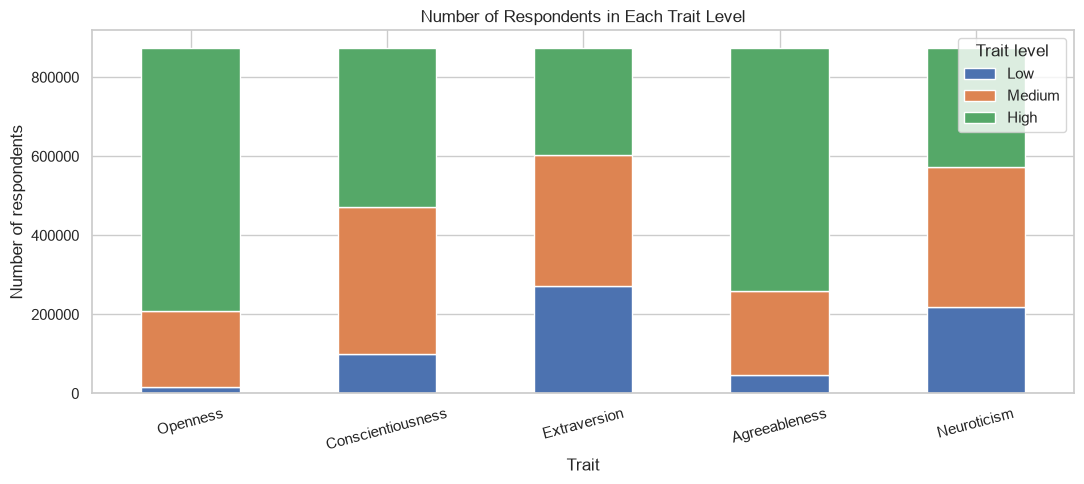

In [9]:
def get_trait_level(score):
    if score < 2.5:
        return "Low"
    elif score < 3.5:
        return "Medium"
    return "High"

level_order = ["Low", "Medium", "High"]
level_counts = pd.DataFrame(index=TRAITS, columns=level_order, dtype=int)
for trait in TRAITS:
    counts = y_all[trait].map(get_trait_level).value_counts()
    for level in level_order:
        level_counts.loc[trait, level] = int(counts.get(level, 0))

level_counts = level_counts.astype(int)
display(level_counts)
level_counts.plot(kind="bar", stacked=True, figsize=(11, 5))
plt.title("Number of Respondents in Each Trait Level")
plt.xlabel("Trait")
plt.ylabel("Number of respondents")
plt.xticks(rotation=15)
plt.legend(title="Trait level")
plt.tight_layout()
plt.show()

### 5.6 Pairwise trait relationships

A sample is used to keep this plot readable and reasonably fast on a laptop.

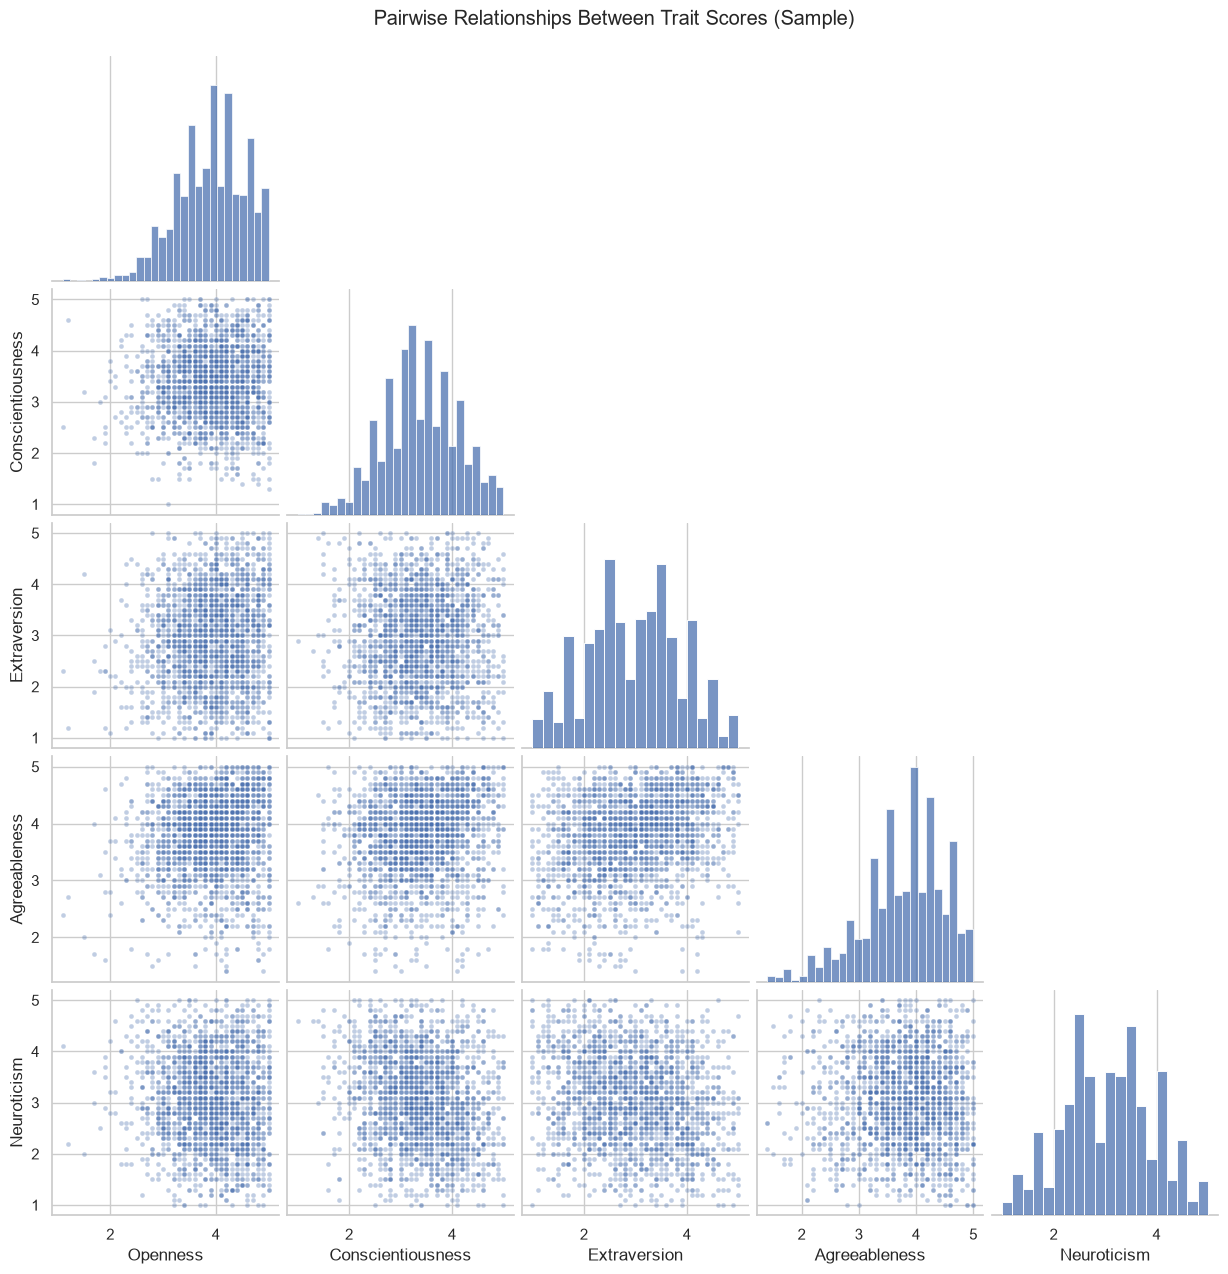

In [10]:
pairplot_sample = y_all.sample(n=min(2000, len(y_all)), random_state=RANDOM_STATE)
pair_grid = sns.pairplot(pairplot_sample, corner=True, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 12})
pair_grid.fig.suptitle("Pairwise Relationships Between Trait Scores (Sample)", y=1.02)
plt.show()

## 6. Prepare the training and test data

A maximum of 150,000 valid rows is used by default to make this a practical mini-project. The split is made before fitting the scaler. The scaler learns its mean and standard deviation from the training inputs only, preventing test-set information from leaking into preprocessing.

In [11]:
MAX_ROWS_FOR_MODEL = 150_000  # Set to None to use every valid row
TEST_SIZE = 0.20

if MAX_ROWS_FOR_MODEL is not None and len(X_all) > MAX_ROWS_FOR_MODEL:
    X_model = X_all.sample(n=MAX_ROWS_FOR_MODEL, random_state=RANDOM_STATE).copy()
    y_model = y_all.loc[X_model.index].copy()
else:
    X_model = X_all.copy()
    y_model = y_all.copy()

X_model = X_model.reset_index(drop=True)
y_model = y_model.reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Rows used for modeling: {len(X_model):,}")
print(f"Training rows:          {len(X_train):,}")
print(f"Test rows:              {len(X_test):,}")
print(f"Input features:         {X_train.shape[1]}")
print(f"Output traits:          {y_train.shape[1]}")

Rows used for modeling: 150,000
Training rows:          120,000
Test rows:              30,000
Input features:         50
Output traits:          5


## 7. Train a simple baseline model

Before the MLP, we train **Linear Regression** as a baseline. This is useful because the target scores are averages of questionnaire items, so their relationship with the inputs is largely linear. A strong baseline is expected and helps put the neural-network result in context.

In [12]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)
print("Linear Regression baseline trained.")

Linear Regression baseline trained.


## 8. Build and train the MLP model

### Architecture

- **Input layer:** 50 questionnaire responses
- **Hidden layer 1:** 64 neurons, ReLU activation
- **Hidden layer 2:** 32 neurons, ReLU activation
- **Output layer:** 5 neurons, linear activation (one predicted score per trait)
- **Loss:** Mean Squared Error (MSE)
- **Optimizer:** Adam
- **Validation:** 15% of the training data
- **Early stopping:** stops when validation loss stops improving, and restores the best weights

This is a multi-output regression task, so classification accuracy is not the correct primary metric.

In [13]:
def build_mlp(input_dim, output_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(output_dim, activation="linear")
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

mlp_model = build_mlp(X_train_scaled.shape[1], y_train.shape[1])
mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           3,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,509 (21.52 KB)

 Trainable params: 5,509 (21.52 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
EPOCHS = 40
BATCH_SIZE = 512

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = mlp_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.15,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 2.3955 - mae: 1.1051 - val_loss: 0.4565 - val_mae: 0.5407
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3544 - mae: 0.4724 - val_loss: 0.2704 - val_mae: 0.4141
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2069 - mae: 0.3580 - val_loss: 0.1493 - val_mae: 0.3058
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1022 - mae: 0.2481 - val_loss: 0.0637 - val_mae: 0.1967
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0409 - mae: 0.1542 - val_loss: 0.0262 - val_mae: 0.1245
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0186 - mae: 0.1036 - val_loss: 0.0139 - val_mae: 0.0899
Epoch 7/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0108 - mae: 0.0785 - val_loss: 0.0088 - val_mae: 0.0708
Epoch 8/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0071 - mae: 0.0636 - val_loss: 0.0061 - val_mae: 0.0587
Epoch 9/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - lo

### 8.1 Training and validation loss

The curves show whether the model learned during training and whether validation loss stopped improving. Early stopping helps avoid unnecessary epochs.

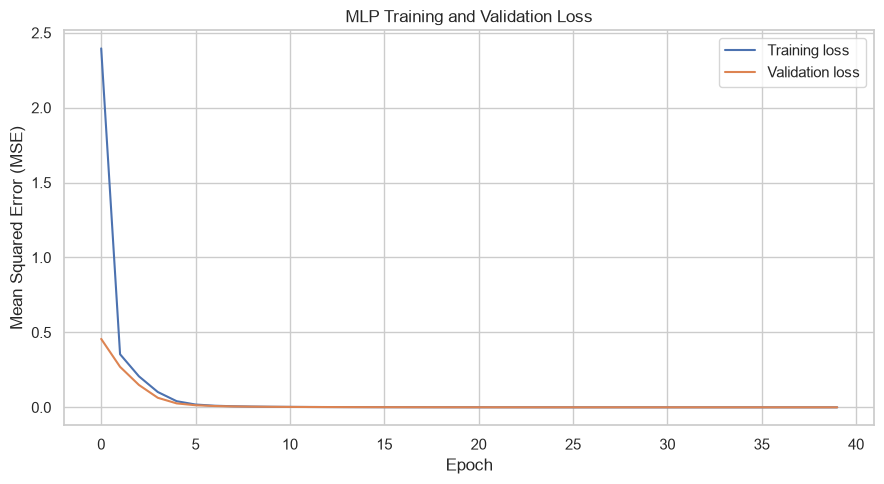

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Evaluate the models

We use three regression metrics:

- **MAE:** average absolute prediction error in score points; lower is better.
- **RMSE:** gives larger errors more weight; lower is better.
- **R²:** how much of the variation in target scores is explained; closer to 1 is better.

Because the score labels are computed from the same responses, high R² should be interpreted as successful score reconstruction rather than independent personality validation.

In [16]:
mlp_predictions = mlp_model.predict(X_test_scaled, verbose=0)

def calculate_metrics(y_true, y_pred):
    mse_value = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mse_value),
        "R2": r2_score(y_true, y_pred, multioutput="uniform_average")
    }

comparison = pd.DataFrame({
    "Linear Regression": calculate_metrics(y_test, linear_predictions),
    "MLP": calculate_metrics(y_test, mlp_predictions)
}).T

display(comparison.round(5))

,MAE,RMSE,R2
Linear Regression,0.00000,0.00000,1.00000
MLP,0.00311,0.00511,0.99995


### 9.1 Metrics for each trait

This table shows where the MLP predicts most accurately and where its errors are higher.

In [17]:
per_trait_metrics = []
for index, trait in enumerate(TRAITS):
    actual = y_test[trait].to_numpy()
    predicted = mlp_predictions[:, index]
    per_trait_metrics.append({
        "Trait": trait,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

per_trait_metrics = pd.DataFrame(per_trait_metrics).set_index("Trait")
display(per_trait_metrics.round(5))

,MAE,RMSE,R2
Trait,,,
Openness,0.00285,0.00559,0.99992
Conscientiousness,0.00342,0.00512,0.99995
Extraversion,0.00288,0.00436,0.99998
Agreeableness,0.00346,0.00552,0.99994
Neuroticism,0.00296,0.00488,0.99997


### 9.2 Actual vs. predicted scores

Points closer to the diagonal line indicate predictions close to the calculated target scores.

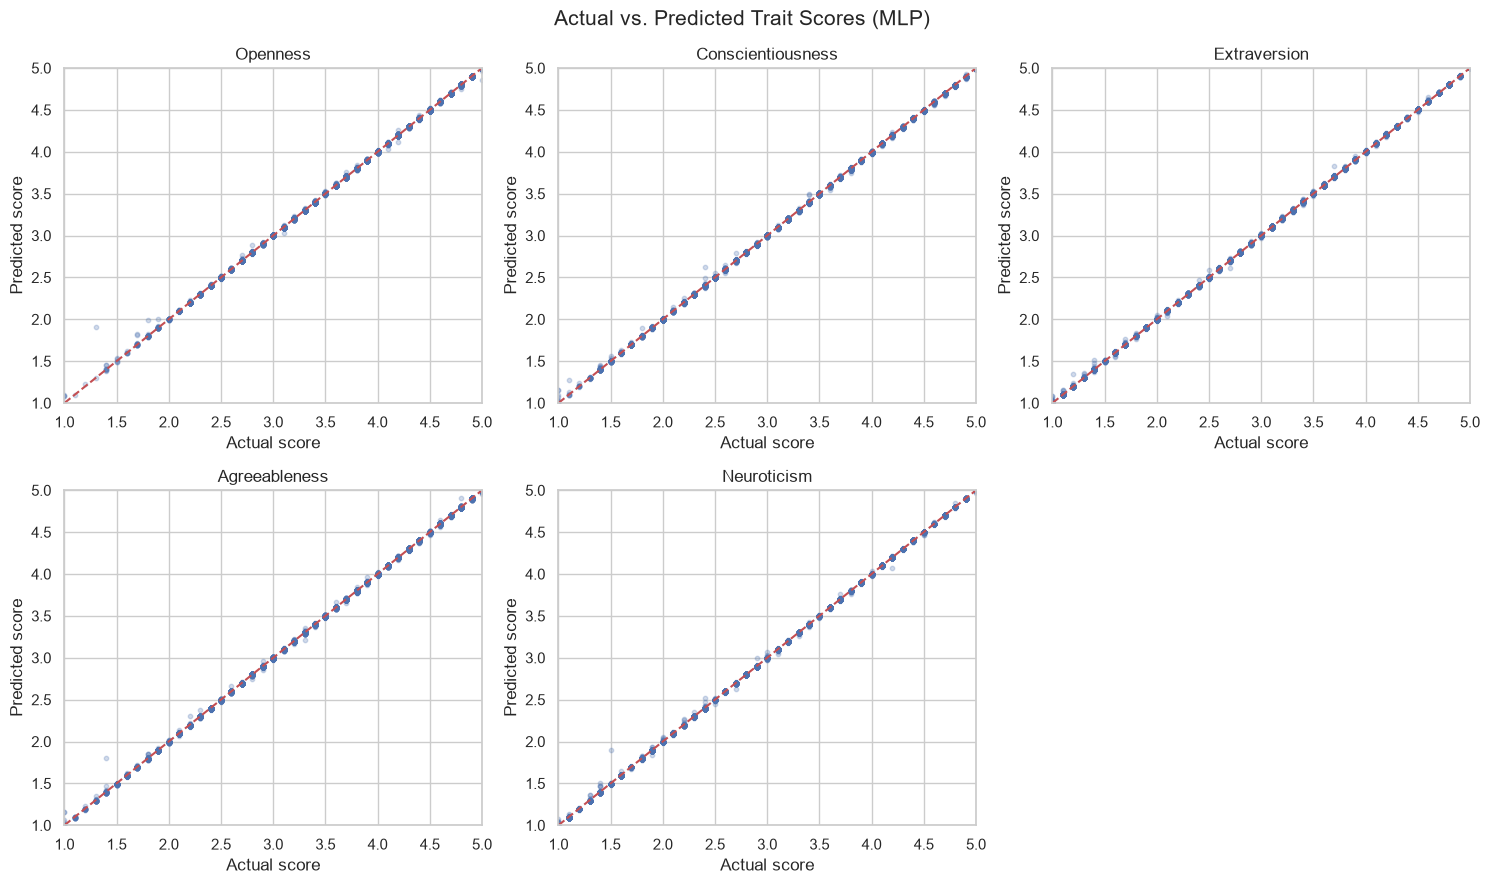

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for index, trait in enumerate(TRAITS):
    actual = y_test[trait].to_numpy()
    predicted = mlp_predictions[:, index]
    axes[index].scatter(actual, predicted, alpha=0.25, s=10)
    axes[index].plot([1, 5], [1, 5], "r--", linewidth=1.5)
    axes[index].set_title(trait)
    axes[index].set_xlabel("Actual score")
    axes[index].set_ylabel("Predicted score")
    axes[index].set_xlim(1, 5)
    axes[index].set_ylim(1, 5)

axes[-1].axis("off")
fig.suptitle("Actual vs. Predicted Trait Scores (MLP)", fontsize=15)
plt.tight_layout()
plt.show()

### 9.3 Prediction residuals

A residual is `actual score - predicted score`. Residual distributions centered around zero indicate that the model is not consistently overpredicting or underpredicting a trait.

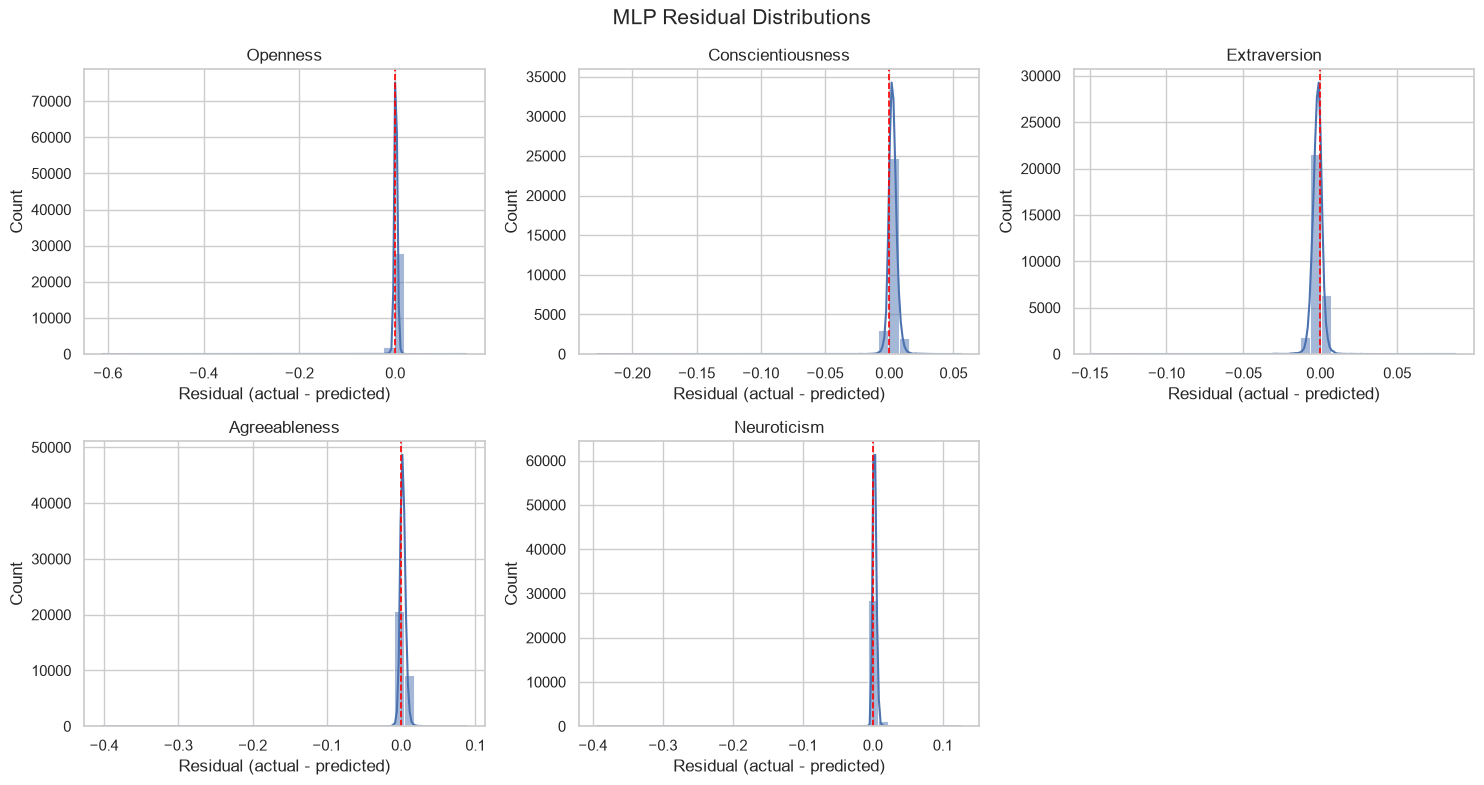

In [19]:
residuals = y_test.to_numpy() - mlp_predictions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for index, trait in enumerate(TRAITS):
    sns.histplot(residuals[:, index], bins=35, kde=True, ax=axes[index])
    axes[index].axvline(0, color="red", linestyle="--", linewidth=1.2)
    axes[index].set_title(trait)
    axes[index].set_xlabel("Residual (actual - predicted)")

axes[-1].axis("off")
fig.suptitle("MLP Residual Distributions", fontsize=15)
plt.tight_layout()
plt.show()

### 9.4 Compare MLP MAE across traits

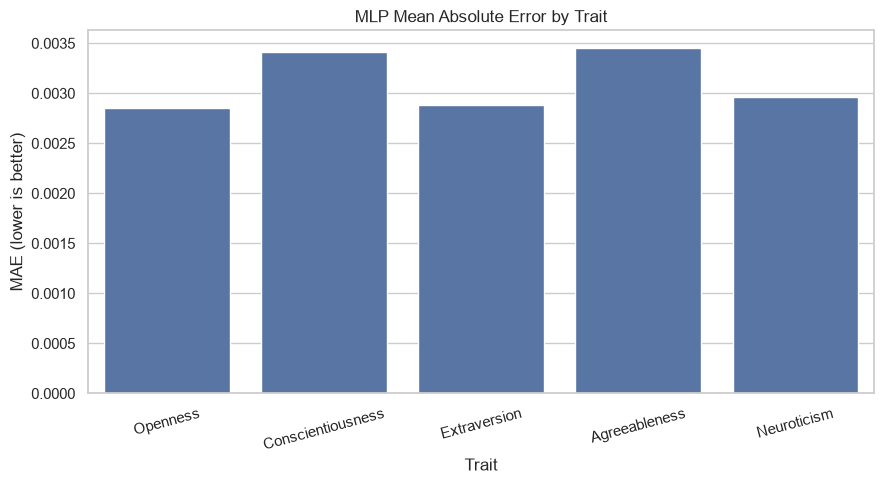

In [20]:
plt.figure(figsize=(9, 5))
sns.barplot(x=per_trait_metrics.index, y=per_trait_metrics["MAE"].values)
plt.title("MLP Mean Absolute Error by Trait")
plt.xlabel("Trait")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Generate a text-based personality profile

The MLP returns five continuous scores. For this small project, each score is converted into a Low, Medium, or High level, then a short template description is selected. The output is transparent and easy to explain during a project presentation.

In [21]:
trait_descriptions = {
    "Openness": {
        "Low": "practical and more comfortable with familiar ideas and routines",
        "Medium": "balances familiar approaches with curiosity about new ideas",
        "High": "curious, imaginative, and interested in exploring new ideas"
    },
    "Conscientiousness": {
        "Low": "flexible and spontaneous, and may prefer less structure",
        "Medium": "reasonably organized while remaining adaptable",
        "High": "organized, dependable, and focused on plans and goals"
    },
    "Extraversion": {
        "Low": "reserved and may feel energized by quieter settings",
        "Medium": "comfortable with a balance of social time and quiet time",
        "High": "sociable, energetic, and comfortable initiating interactions"
    },
    "Agreeableness": {
        "Low": "direct and independent, and may question others' viewpoints",
        "Medium": "cooperative while still maintaining personal boundaries",
        "High": "considerate, cooperative, and attentive to other people's feelings"
    },
    "Neuroticism": {
        "Low": "may generally experience fewer stress-related emotional reactions",
        "Medium": "may experience a mix of calm periods and occasional worry or stress",
        "High": "may notice worry or stress-related emotional reactions more often"
    }
}

def generate_personality_summary(trait_scores):
    """Turn a dictionary of trait scores into a short, readable text profile."""
    parts = []
    for trait in TRAITS:
        score = float(trait_scores[trait])
        level = get_trait_level(score)
        description = trait_descriptions[trait][level]
        parts.append(f"{trait} ({level}, {score:.2f}/5): {description}.")
    return "Personality Trait Overview\n" + "\n".join(f"- {part}" for part in parts)


def predict_personality_from_answers(answers):
    """Predict scores from a dict of raw item responses such as {'EXT1': 4, ...}."""
    missing = [column for column in question_columns if column not in answers]
    if missing:
        raise ValueError(f"Missing answers for {len(missing)} items: {missing[:10]}")

    input_row = pd.DataFrame([[answers[column] for column in question_columns]], columns=question_columns)
    input_row = input_row.apply(pd.to_numeric, errors="coerce")
    if input_row.isna().any().any() or not input_row.isin([1, 2, 3, 4, 5]).all().all():
        raise ValueError("Every answer must be a number from 1 to 5.")

    scaled_row = scaler.transform(input_row)
    predicted_scores = mlp_model.predict(scaled_row, verbose=0)[0]
    predicted_scores = np.clip(predicted_scores, 1, 5)  # keep scores on the 1–5 response scale
    score_dict = {trait: float(score) for trait, score in zip(TRAITS, predicted_scores)}
    return score_dict, generate_personality_summary(score_dict)

### 10.1 Example prediction

This example uses a held-out row from the test set. It is provided to show the complete prediction-to-text workflow; it is not an independent validation of personality descriptions.

Predicted trait scores:
Openness: 3.39/5
Conscientiousness: 2.70/5
Extraversion: 3.80/5
Agreeableness: 2.80/5
Neuroticism: 3.30/5

Generated profile:

Personality Trait Overview
- Openness (Medium, 3.39/5): balances familiar approaches with curiosity about new ideas.
- Conscientiousness (Medium, 2.70/5): reasonably organized while remaining adaptable.
- Extraversion (High, 3.80/5): sociable, energetic, and comfortable initiating interactions.
- Agreeableness (Medium, 2.80/5): cooperative while still maintaining personal boundaries.
- Neuroticism (Medium, 3.30/5): may experience a mix of calm periods and occasional worry or stress.


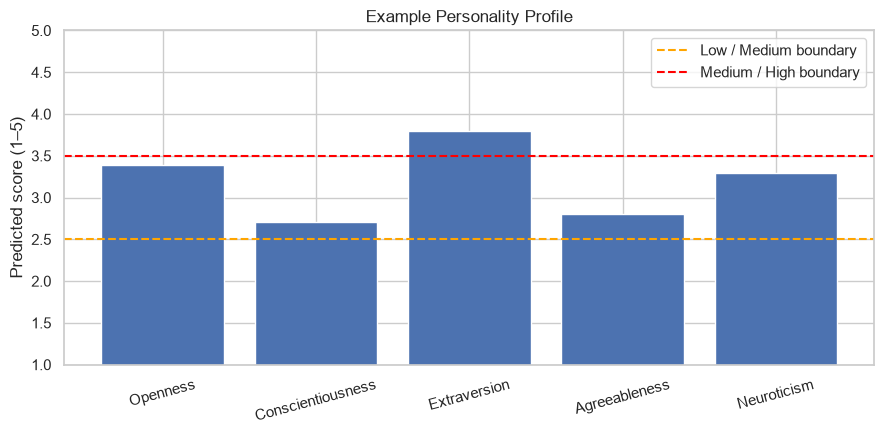

In [22]:
example_answers = X_test.iloc[0].to_dict()
example_scores, example_summary = predict_personality_from_answers(example_answers)

print("Predicted trait scores:")
for trait, score in example_scores.items():
    print(f"{trait}: {score:.2f}/5")

print("\nGenerated profile:\n")
print(example_summary)

plt.figure(figsize=(9, 4.5))
plt.bar(example_scores.keys(), example_scores.values())
plt.axhline(2.5, color="orange", linestyle="--", label="Low / Medium boundary")
plt.axhline(3.5, color="red", linestyle="--", label="Medium / High boundary")
plt.ylim(1, 5)
plt.ylabel("Predicted score (1–5)")
plt.title("Example Personality Profile")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

### 10.2 Optional: answer the 50-item questionnaire yourself

Run the next cell to define the interactive function. Then run `run_interactive_test()` in a separate cell. Each item accepts a response from **1 to 5** (`1 = Disagree`, `3 = Neutral`, `5 = Agree`; 2 and 4 are intermediate responses). This asks all 50 items, so it is optional.

In [23]:
QUESTION_TEXT = {
    "EXT1": "I am the life of the party.",
    "EXT2": "I don't talk a lot.",
    "EXT3": "I feel comfortable around people.",
    "EXT4": "I keep in the background.",
    "EXT5": "I start conversations.",
    "EXT6": "I have little to say.",
    "EXT7": "I talk to a lot of different people at parties.",
    "EXT8": "I don't like to draw attention to myself.",
    "EXT9": "I don't mind being the center of attention.",
    "EXT10": "I am quiet around strangers.",
    "EST1": "I get stressed out easily.",
    "EST2": "I am relaxed most of the time.",
    "EST3": "I worry about things.",
    "EST4": "I seldom feel blue.",
    "EST5": "I am easily disturbed.",
    "EST6": "I get upset easily.",
    "EST7": "I change my mood a lot.",
    "EST8": "I have frequent mood swings.",
    "EST9": "I get irritated easily.",
    "EST10": "I often feel blue.",
    "AGR1": "I feel little concern for others.",
    "AGR2": "I am interested in people.",
    "AGR3": "I insult people.",
    "AGR4": "I sympathize with others' feelings.",
    "AGR5": "I am not interested in other people's problems.",
    "AGR6": "I have a soft heart.",
    "AGR7": "I am not really interested in others.",
    "AGR8": "I take time out for others.",
    "AGR9": "I feel others' emotions.",
    "AGR10": "I make people feel at ease.",
    "CSN1": "I am always prepared.",
    "CSN2": "I leave my belongings around.",
    "CSN3": "I pay attention to details.",
    "CSN4": "I make a mess of things.",
    "CSN5": "I get chores done right away.",
    "CSN6": "I often forget to put things back in their proper place.",
    "CSN7": "I like order.",
    "CSN8": "I shirk my duties.",
    "CSN9": "I follow a schedule.",
    "CSN10": "I am exacting in my work.",
    "OPN1": "I have a rich vocabulary.",
    "OPN2": "I have difficulty understanding abstract ideas.",
    "OPN3": "I have a vivid imagination.",
    "OPN4": "I am not interested in abstract ideas.",
    "OPN5": "I have excellent ideas.",
    "OPN6": "I do not have a good imagination.",
    "OPN7": "I am quick to understand things.",
    "OPN8": "I use difficult words.",
    "OPN9": "I spend time reflecting on things.",
    "OPN10": "I am full of ideas."
}

def run_interactive_test():
    answers = {}
    print("Answer each statement from 1 to 5: 1=Disagree, 3=Neutral, 5=Agree.\n")
    for item in question_columns:
        while True:
            raw_value = input(f"{item}: {QUESTION_TEXT[item]} (1-5): ").strip()
            try:
                value = int(raw_value)
                if value in [1, 2, 3, 4, 5]:
                    answers[item] = value
                    break
            except ValueError:
                pass
            print("Please enter 1, 2, 3, 4, or 5.")

    scores, summary = predict_personality_from_answers(answers)
    print("\nPredicted trait scores:")
    for trait, score in scores.items():
        print(f"{trait}: {score:.2f}/5")
    print("\nGenerated profile:\n")
    print(summary)
    return scores, summary

# When you are ready, run this in a new cell:
# scores, summary = run_interactive_test()

## 11. Save the trained model and supporting files

The `output` folder will contain the trained Keras model, fitted scaler, metadata needed to keep the feature order consistent, and metric tables. Keep the scaler and feature order with the model when making predictions later.

In [24]:
model_path = "output/personality_mlp_model.keras"
scaler_path = "output/personality_input_scaler.pkl"
metadata_path = "output/personality_model_metadata.pkl"
metrics_path = "output/model_metrics.csv"
trait_metrics_path = "output/mlp_trait_metrics.csv"

mlp_model.save(model_path)
joblib.dump(scaler, scaler_path)
joblib.dump({
    "question_columns": question_columns,
    "traits": TRAITS,
    "trait_prefixes": TRAIT_PREFIX,
    "reverse_items": REVERSE_ITEMS,
    "trait_descriptions": trait_descriptions
}, metadata_path)
comparison.to_csv(metrics_path, index=True)
per_trait_metrics.to_csv(trait_metrics_path, index=True)

print("Saved files:")
for path in [model_path, scaler_path, metadata_path, metrics_path, trait_metrics_path]:
    print("-", path)

Saved files:
- output/personality_mlp_model.keras
- output/personality_input_scaler.pkl
- output/personality_model_metadata.pkl
- output/model_metrics.csv
- output/mlp_trait_metrics.csv


## 12. Final project summary

At the end of this notebook, you have:

- A cleaned input table containing the 50 valid questionnaire responses.
- Five target scores using reverse-scored items and a consistent 1–5 scale.
- Exploratory visualizations for response quality, score distributions, correlations, response means, trait levels, and pairwise relationships.
- A Linear Regression baseline and a small MLP trained on a train/test split.
- Overall and per-trait regression metrics, training curves, actual-vs-predicted plots, and residual plots.
- A text profile generator plus an optional interactive questionnaire function.
- Saved model/scaler/metadata/metric files in the `output` directory.

### How to explain the result during your presentation

The MLP predicts the five continuous trait scores from the 50 questionnaire answers. The predicted scores are converted into Low, Medium, or High levels, which select a short description for each trait. The evaluation demonstrates how well the model reconstructs the score calculation on held-out rows. Because those targets were derived from the same questionnaire answers, report MAE, RMSE, and R² as **score-reconstruction metrics**, not as proof of personality accuracy.

## References

- **Dataset:** [Kaggle — Big Five Personality Test](https://www.kaggle.com/datasets/tunguz/big-five-personality-test)
- **Questionnaire item descriptions:** [Open Psychometrics — IPIP-BFFM](https://openpsychometrics.org/tests/IPIP-BFFM/)
- **Reverse-scoring key:** [IPIP — Big-Five Factor Markers](https://ipip.ori.org/newBigFive5broadKey.htm)

The item scoring directions in this notebook follow the IPIP key. The Neuroticism target is created by reversing the Emotional Stability direction so higher values represent more neuroticism-related responses.
